# Demonstrate a working controller

## 1. Set up the notebook

Do imports.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, IFrame, HTML
from ae483.tools import *
from ae483.mytools import *
from ae483.design import *

Define name of file with flight data.

In [4]:
filename = 'demonstration_data.json'

## 2. Check mocap coverage

Check coverage of mocap data.

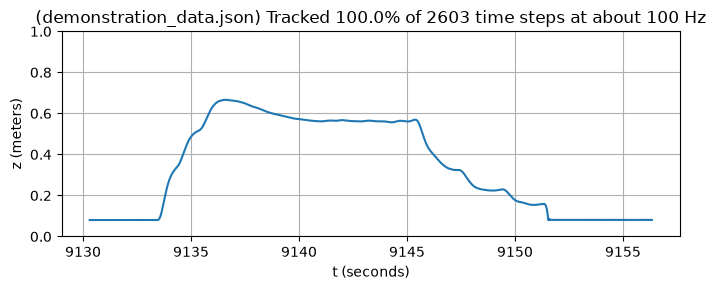

In [5]:
check_mocap_coverage(filename)

## 3. Show results

Load flight data.

In [6]:
raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data(filename)

Resample and parse drone data.

In [8]:
data_drone = resample_data_drone(
    raw_data_drone,
    t_min_offset=5., # <-- FIXME
    t_max_offset=3., # <-- FIXME
)

# time
t = data_drone['time']

# position
p_x = data_drone['ae483log.p_x']
p_y = data_drone['ae483log.p_y']
p_z = data_drone['ae483log.p_z']

# desired position
p_x_des = data_drone['ae483log.p_x_des']
p_y_des = data_drone['ae483log.p_y_des']
p_z_des = data_drone['ae483log.p_z_des']

# orientation
psi = data_drone['ae483log.psi']
theta = data_drone['ae483log.theta']
phi = data_drone['ae483log.phi']

# motor power commands
m_1 = data_drone['ae483log.m_1']
m_2 = data_drone['ae483log.m_2']
m_3 = data_drone['ae483log.m_3']
m_4 = data_drone['ae483log.m_4']

Resample and parse mocap data (with an optimal time shift and with coordinate transformation).

In [9]:
data_mocap = sync_data_mocap(
    raw_data_mocap,
    t,
    p_z,
    do_transform=True,      # <-- whether to align mocap data in space
    t_min_offset=0.,        # <-- how many seconds of mocap data to delete at the start
    t_shift_rng=1.,         # <-- range of time shifts over which to search
    t_shift_res=0.05,       # <-- resolution at which to sample time shifts in the range
)

p_x_mocap = data_mocap['x']
p_y_mocap = data_mocap['y']
p_z_mocap = data_mocap['z']
psi_mocap = data_mocap['yaw']
theta_mocap = data_mocap['pitch']
phi_mocap = data_mocap['roll']

Plot $x, y$ data.

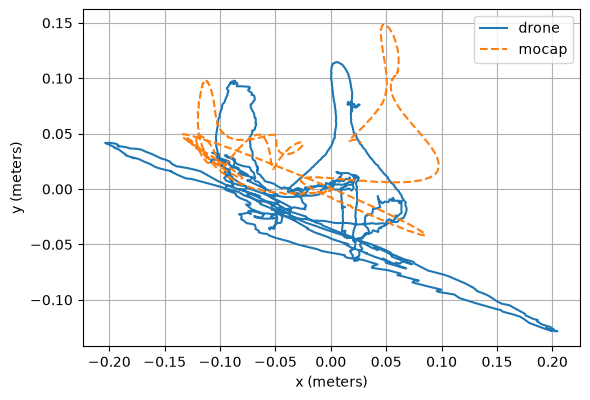

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6), tight_layout=True)
ax.plot(p_x, p_y, label='drone')
ax.plot(p_x_mocap, p_y_mocap, '--', label='mocap')
ax.set_aspect('equal')
ax.set_xlabel('x (meters)')
ax.set_ylabel('y (meters)')
ax.legend()
ax.grid()

Plot all data.

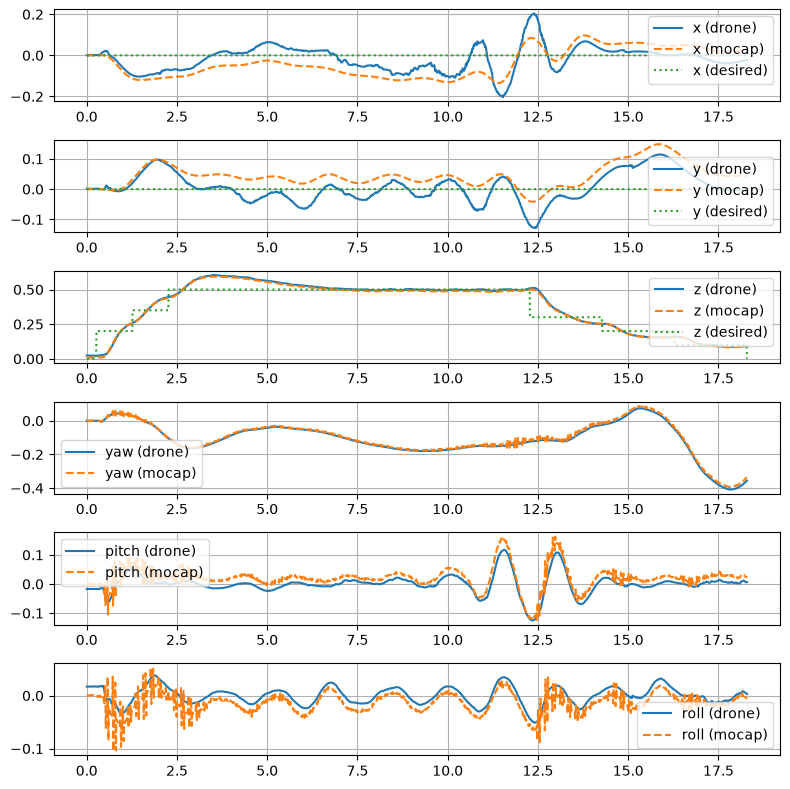

In [11]:
fig, (ax_x, ax_y, ax_z, ax_psi, ax_theta, ax_phi) = plt.subplots(6, 1, figsize=(8, 8), tight_layout=True)

ax_x.plot(t, p_x, label='x (drone)')
ax_x.plot(t, p_x_mocap, '--', label='x (mocap)')
ax_x.plot(t, p_x_des, ':', label='x (desired)')
ax_x.legend()
ax_x.grid()

ax_y.plot(t, p_y, label='y (drone)')
ax_y.plot(t, p_y_mocap, '--', label='y (mocap)')
ax_y.plot(t, p_y_des, ':', label='y (desired)')
ax_y.legend()
ax_y.grid()

ax_z.plot(t, p_z, label='z (drone)')
ax_z.plot(t, p_z_mocap, '--', label='z (mocap)')
ax_z.plot(t, p_z_des, ':', label='z (desired)')
ax_z.legend()
ax_z.grid()

ax_psi.plot(t, psi, label='yaw (drone)')
ax_psi.plot(t, psi_mocap, '--', label='yaw (mocap)')
ax_psi.legend()
ax_psi.grid()

ax_theta.plot(t, theta, label='pitch (drone)')
ax_theta.plot(t, theta_mocap, '--', label='pitch (mocap)')
ax_theta.legend()
ax_theta.grid()

ax_phi.plot(t, phi, label='roll (drone)')
ax_phi.plot(t, phi_mocap, '--', label='roll (mocap)')
ax_phi.legend()
ax_phi.grid()

Show the gains that were used to produce these results.

In [12]:
show_gains(filename)

Control gains, designed 2026-10-14T14:55:46:
tau_x_cmd:     eq   0.0000    p_y  -0.0034    phi   0.0115    v_y  -0.0031    w_x   0.0023  tau_x   1.5991    e_y  -0.0015
tau_y_cmd:     eq   0.0000    p_x   0.0034  theta   0.0115    v_x   0.0031    w_y   0.0023  tau_y   1.5837    e_x   0.0015
    tau_z:     eq   0.0000    psi   0.0003    w_z   0.0004
      f_z:     eq   0.3335    p_z   0.3246    v_z   0.2256    e_z   0.1697


Show links to a video of your hardware flight test (change the url as appropriate) that was previously uploaded to [Illinois Mediaspace](https://mediaspace.illinois.edu/) and published as **Unlisted**.

In [13]:
# FIXME (REPLACE URL TO SHOW A VIDEO OF YOUR FLIGHT)
mediaspace('https://mediaspace.illinois.edu/media/t/1_dsjww02t')

**Modify this cell** to describe three things:

* Your design.

**Our controller design kept the Q matrix as the identity matrix. After finding the stabilizing ratios between the taus and force, we multipled the entire R matrix by 8 to decrease the motor command saturation. Our design process was iterative by flying the drone under certain conditions and gradually tuning.**

* Your flight test.

**Our flight test was within the required variation of each parameter. The drone was most unstable near the end of the hover and on the landing sequence, resulting in some yaw that could not be fully ironed out.**

* Your results, in particular making clear if these results satisfy requirements. (Feel free to add code to verify these requirements.)

**Yes, our results satisfy the requirements.**

## 4. Reflect

**Modify the text in this cell** to describe, in at least two or three sentences, the biggest struggle you had (with the technical material, with collaboration, etc.) and the most important thing that you learned. Look back at your reflections from the first four labs — have you taken a step forward? Think ahead to next week, when you will be asked to further improve the performance of your controller — what might you do in order to make that process go well?

**We need not struggle understanding or implementing the code for the controller. Our struggles came in fine-tuning the ratios between the taus and force to reach maximize stability. This took lots of time to understand how fine changes could drastically change the flight, and, further, how flying at different battery voltages can change the performance of our controller.**